# 03 - Modelling

Model comparison, hyperparameter optimisation with Optuna, imbalance and threshold choices, and the final
held-out evaluation of the **deployed model** (`models/churn_model.joblib`, produced by
`python -m src.models.train`).

**Protocol** (identical to `src/models/train.py`): 80/20 stratified split (seed 42); model selection by
5-fold CV on the training part; the test set is used once, at the end, with a threshold chosen from
training out-of-fold predictions. Metric of record is **PR-AUC** (average precision), because churn is the
minority class (26.5%); ROC-AUC, Brier score, precision, recall and F1 are reported alongside.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent          # notebooks/ lives one level below the project root
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4), "axes.titlesize": 11})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

In [2]:
import json
import joblib
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve, confusion_matrix
from lightgbm import LGBMClassifier

from src.data.load import load_raw
from src.data.preprocess import clean
from src.features.build_features import build_features, TARGET
from src.models.evaluate import best_f1_threshold, evaluate
from src.models.train import make_xgb, make_logreg, make_preprocessor, SEED

df = clean(load_raw())
X, y = build_features(df), df[TARGET].astype(int).reset_index(drop=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

meta = json.loads((ROOT / "models" / "metadata.json").read_text())
print("deployed model:", meta["model_version"], "| trained", meta["trained_at"])
print("train", X_train.shape, "churn", round(y_train.mean(), 3), "| test", X_test.shape, "churn", round(y_test.mean(), 3))

deployed model: xgboost-20261117-f6239cb7 | trained 2026-11-17T12:08:32+00:00
train (5634, 19) churn 0.265 | test (1409, 19) churn 0.265


## 1. Model comparison (5-fold CV on the training part)

The XGBoost "tuned" row uses the parameters saved by the Optuna run in `train.py` (reproduced in section 2).
Those parameters were *selected* on these same folds, so its CV score is slightly optimistic; the fair
comparison is the held-out test set in section 5.

In [3]:
rf = Pipeline([("prep", make_preprocessor(False)), ("model", RandomForestClassifier(n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=SEED))])
lgbm = Pipeline([("prep", make_preprocessor(False)), ("model", LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, min_child_samples=20, verbose=-1, random_state=SEED))])
dummy = Pipeline([("prep", make_preprocessor(False)), ("model", DummyClassifier(strategy="prior"))])

models = {
    "dummy (class prior)": dummy,
    "logistic regression": make_logreg(),
    "random forest": rf,
    "LightGBM": lgbm,
    "XGBoost default": make_xgb(),
    "XGBoost tuned (saved params)": make_xgb(meta["best_params"]),
}
rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring={"pr": "average_precision", "roc": "roc_auc", "brier": "neg_brier_score"})
    rows.append((name, r["test_pr"].mean(), r["test_pr"].std(), r["test_roc"].mean(), -r["test_brier"].mean()))
cmp = pd.DataFrame(rows, columns=["model", "PR-AUC", "PR sd", "ROC-AUC", "Brier"]).set_index("model")
cmp.round(4)

,PR-AUC,PR sd,ROC-AUC,Brier
model,,,,
dummy (class prior),0.2654,0.0001,0.5000,0.1949
logistic regression,0.6600,0.0195,0.8460,0.1653
random forest,0.6573,0.0226,0.8445,0.1355
LightGBM,0.6630,0.0192,0.8446,0.1357
XGBoost default,0.6310,0.0135,0.8241,0.1492
XGBoost tuned (saved params),0.6740,0.0209,0.8515,0.1329


## 2. Hyperparameter optimisation with Optuna

Same search as `train.py`: 40 trials, TPE sampler (seed 42), objective = mean 5-fold CV PR-AUC on the
training part, 9 XGBoost parameters. Re-running it here should reproduce the saved parameters.

In [4]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    p = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 1.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
    }
    r = cross_validate(make_xgb(p), X_train, y_train, cv=cv, scoring="average_precision")
    return float(r["test_score"].mean())

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=40)
print(f"best CV PR-AUC: {study.best_value:.4f} (trial {study.best_trial.number})")
print("reproduces saved parameters:", study.best_params == meta["best_params"])
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in study.best_params.items()})

best CV PR-AUC: 0.6740 (trial 36)
reproduces saved parameters: True
{'n_estimators': 450, 'learning_rate': 0.0491, 'max_depth': 4, 'min_child_weight': 7, 'subsample': 0.6288, 'colsample_bytree': 0.7037, 'reg_lambda': 0.7628, 'reg_alpha': 0.3299, 'gamma': 4.9291}


default XGBoost CV PR-AUC 0.6310  ->  Optuna best 0.6740  (gain +0.0430)
trials within 0.005 of the best: 37 of 40


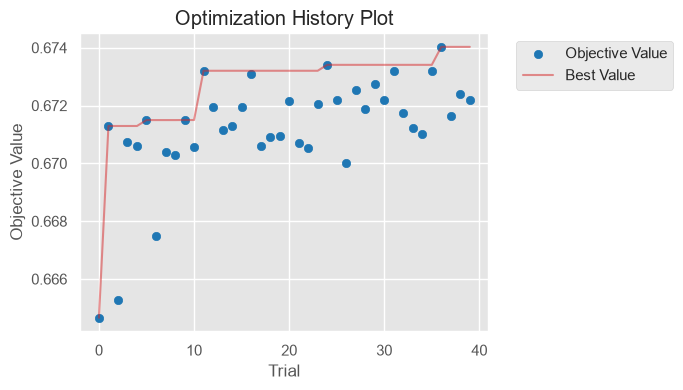

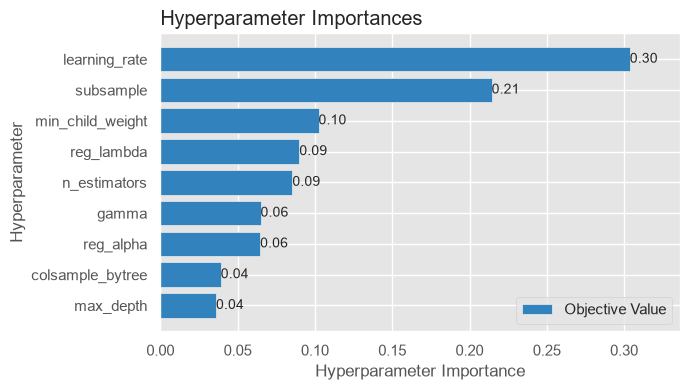

In [5]:
default_pr = cmp.loc["XGBoost default", "PR-AUC"]
print(f"default XGBoost CV PR-AUC {default_pr:.4f}  ->  Optuna best {study.best_value:.4f}  (gain {study.best_value - default_pr:+.4f})")
trials = study.trials_dataframe()[["number", "value"]]
print("trials within 0.005 of the best:", int((trials["value"] >= study.best_value - 0.005).sum()), "of", len(trials))
optuna.visualization.matplotlib.plot_optimization_history(study); plt.tight_layout(); plt.show()
optuna.visualization.matplotlib.plot_param_importances(study); plt.tight_layout(); plt.show()

## 3. Class imbalance: re-weighting or threshold?

`scale_pos_weight` makes the model care more about churners, but it distorts the predicted probabilities,
which the app shows to users as "churn probability". Compare calibration as well as ranking.

In [6]:
pos_w = float((y_train == 0).sum() / (y_train == 1).sum())
rows = []
for name, params in {"tuned, no re-weighting": meta["best_params"], f"tuned + scale_pos_weight={pos_w:.2f}": {**meta["best_params"], "scale_pos_weight": pos_w}}.items():
    oof = cross_val_predict(make_xgb(params), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    pred = oof >= 0.5
    rows.append((name, average_precision_score(y_train, oof), roc_auc_score(y_train, oof), float(np.mean((oof - y_train) ** 2)),
                 oof.mean(), (pred & (y_train == 1)).sum() / (y_train == 1).sum(), (pred & (y_train == 1)).sum() / max(pred.sum(), 1)))
pd.DataFrame(rows, columns=["variant", "PR-AUC", "ROC-AUC", "Brier", "mean predicted p", "recall@0.5", "precision@0.5"]).set_index("variant").round(4).assign(true_churn_rate=round(y_train.mean(), 4))

,PR-AUC,ROC-AUC,Brier,mean predicted p,recall@0.5,precision@0.5,true_churn_rate
variant,,,,,,,
"tuned, no re-weighting",0.6699,0.8508,0.1329,0.2652,0.5351,0.6639,0.2654
tuned + scale_pos_weight=2.77,0.6652,0.8468,0.1600,0.3989,0.7866,0.5234,0.2654


## 4. Decision threshold

Chosen on the training **out-of-fold** predictions (never on test): the cut-off that maximises F1.
A business view follows, with *illustrative* costs (assumptions, not company data).

F1-optimal threshold on OOF: 0.345  | stored in metadata: 0.345


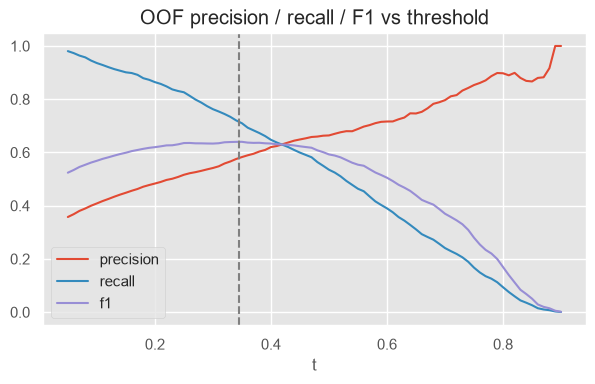

,accuracy,precision,recall,f1
thr=0.30,0.766,0.542,0.763,0.633
thr=0.34,0.787,0.580,0.718,0.641
thr=0.50,0.805,0.664,0.535,0.593


In [7]:
tuned = make_xgb(meta["best_params"])
oof = cross_val_predict(tuned, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thr = best_f1_threshold(y_train, oof)
print(f"F1-optimal threshold on OOF: {thr:.3f}  | stored in metadata: {meta['threshold']:.3f}")

grid = np.linspace(0.05, 0.9, 86)
m = pd.DataFrame([{k: v for k, v in evaluate(y_train, oof, t).items() if k in ("precision", "recall", "f1")} | {"t": t} for t in grid]).set_index("t")
m.plot(figsize=(7, 3.8)); plt.axvline(thr, color="grey", ls="--"); plt.title("OOF precision / recall / F1 vs threshold"); plt.show()
pd.DataFrame({f"thr={t:.2f}": {k: v for k, v in evaluate(y_train, oof, t).items() if k in ("precision", "recall", "f1", "accuracy")} for t in (0.3, thr, 0.5)}).T.round(3)

with V=500, offer cost C=50, success S=30%: best threshold 0.35 (net benefit 68,100) vs F1-optimal 0.34 (net benefit 68,400) vs 'contact nobody' 0


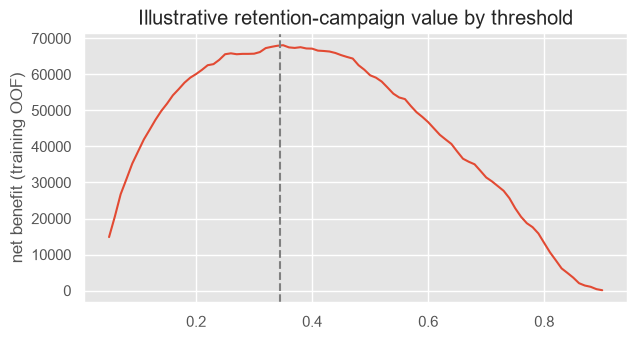

In [8]:
# ILLUSTRATIVE assumptions: value of a retained customer, cost of a retention offer, offer success rate
V, C, S = 500.0, 50.0, 0.30
def net_benefit(t):
    flag = oof >= t
    tp, fp = int((flag & (y_train == 1)).sum()), int((flag & (y_train == 0)).sum())
    return tp * S * V - (tp + fp) * C
nb = pd.Series({t: net_benefit(t) for t in grid})
print(f"with V={V:.0f}, offer cost C={C:.0f}, success S={S:.0%}: best threshold {nb.idxmax():.2f} (net benefit {nb.max():,.0f}) "
      f"vs F1-optimal {thr:.2f} (net benefit {net_benefit(thr):,.0f}) vs 'contact nobody' 0")
nb.plot(figsize=(7, 3.5)); plt.axvline(thr, color="grey", ls="--"); plt.ylabel("net benefit (training OOF)"); plt.title("Illustrative retention-campaign value by threshold"); plt.show()

## 5. Final held-out evaluation of the deployed model

Loaded from `models/churn_model.joblib`. The saved metrics in `metadata.json` must match what is recomputed
here from the same split.

In [9]:
art = joblib.load(ROOT / "models" / "churn_model.joblib")
pipe, dthr = art["pipeline"], art["metadata"]["threshold"]
proba = pipe.predict_proba(X_test)[:, 1]
test = evaluate(y_test, proba, dthr)
saved = meta["metrics"]["xgboost_tuned"]["test"]
print("recomputed == metadata.json:", all(abs(test[k] - saved[k]) < 1e-9 for k in ("roc_auc", "pr_auc", "f1", "recall", "precision")))

lr = make_logreg().fit(X_train, y_train)
p_lr = lr.predict_proba(X_test)[:, 1]
lr_thr = meta["metrics"]["logistic_regression"]["test"]["threshold"]
table = pd.DataFrame({"deployed XGBoost": evaluate(y_test, proba, dthr), "logistic regression": evaluate(y_test, p_lr, lr_thr)}).drop("confusion").astype(float)
table.round(3)

recomputed == metadata.json: True


,deployed XGBoost,logistic regression
roc_auc,0.849,0.842
pr_auc,0.666,0.633
brier,0.134,0.169
threshold,0.345,0.575
accuracy,0.779,0.762
precision,0.565,0.539
recall,0.727,0.725
f1,0.636,0.618


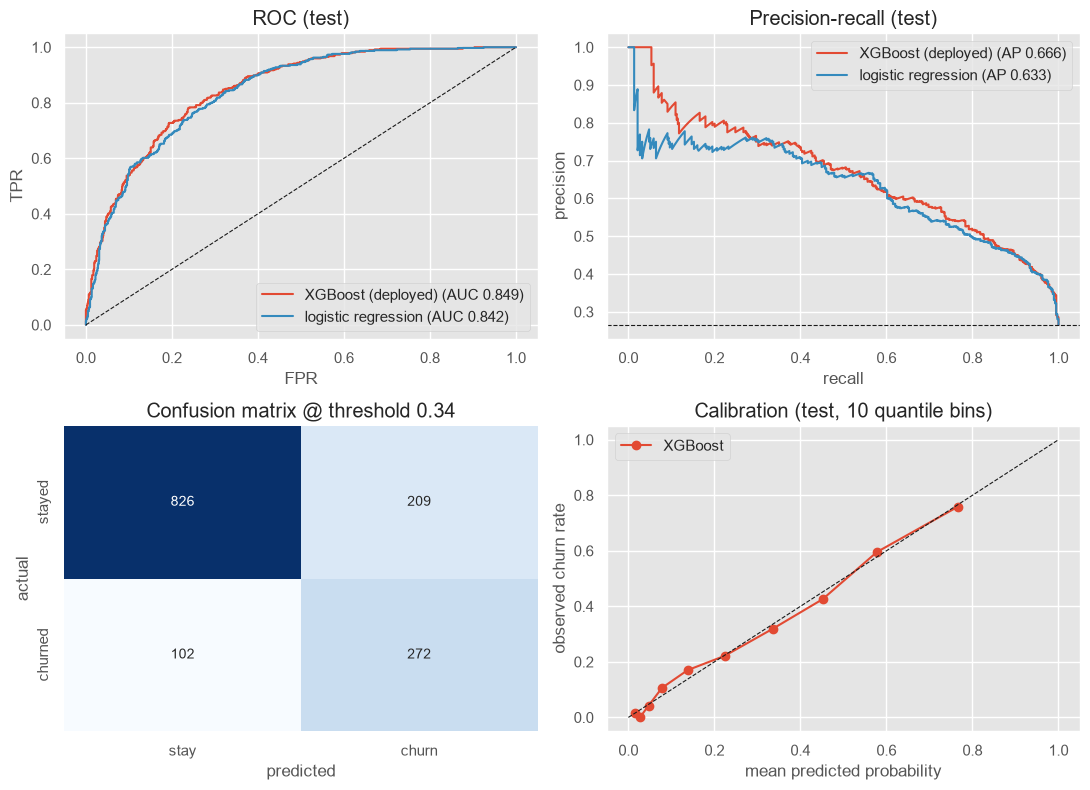

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for p, name in ((proba, "XGBoost (deployed)"), (p_lr, "logistic regression")):
    fpr, tpr, _ = roc_curve(y_test, p); axes[0, 0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); axes[0, 1].plot(rc, pr, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0, 0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0, 0].set(title="ROC (test)", xlabel="FPR", ylabel="TPR"); axes[0, 0].legend()
axes[0, 1].axhline(y_test.mean(), color="k", ls="--", lw=0.8); axes[0, 1].set(title="Precision-recall (test)", xlabel="recall", ylabel="precision"); axes[0, 1].legend()
cm = confusion_matrix(y_test, proba >= dthr)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, 0], xticklabels=["stay", "churn"], yticklabels=["stayed", "churned"])
axes[1, 0].set(title=f"Confusion matrix @ threshold {dthr:.2f}", xlabel="predicted", ylabel="actual")
from sklearn.calibration import calibration_curve
fp_, mp_ = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
axes[1, 1].plot(mp_, fp_, "o-", label="XGBoost"); axes[1, 1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1, 1].set(title="Calibration (test, 10 quantile bins)", xlabel="mean predicted probability", ylabel="observed churn rate"); axes[1, 1].legend()
plt.tight_layout(); plt.show()

### Is the gain over logistic regression real?

With 1,409 test customers, a single test-set number is noisy. A paired bootstrap (same resampled customers
for both models) gives a confidence interval for the *difference*.

In [11]:
rng = np.random.default_rng(SEED)
yt, n = y_test.to_numpy(), len(y_test)
d_pr, d_roc, pr_x, roc_x = [], [], [], []
for _ in range(1000):
    i = rng.integers(0, n, n)
    if yt[i].min() == yt[i].max():
        continue
    a_x, a_l = average_precision_score(yt[i], proba[i]), average_precision_score(yt[i], p_lr[i])
    r_x, r_l = roc_auc_score(yt[i], proba[i]), roc_auc_score(yt[i], p_lr[i])
    d_pr.append(a_x - a_l); d_roc.append(r_x - r_l); pr_x.append(a_x); roc_x.append(r_x)
ci = lambda v: f"[{np.percentile(v, 2.5):+.3f}, {np.percentile(v, 97.5):+.3f}]"
print(f"XGBoost PR-AUC 95% CI:  [{np.percentile(pr_x, 2.5):.3f}, {np.percentile(pr_x, 97.5):.3f}]   ROC-AUC 95% CI: [{np.percentile(roc_x, 2.5):.3f}, {np.percentile(roc_x, 97.5):.3f}]")
print(f"XGBoost - LogReg  PR-AUC difference  95% CI: {ci(d_pr)}   (mean {np.mean(d_pr):+.3f})")
print(f"XGBoost - LogReg  ROC-AUC difference 95% CI: {ci(d_roc)}   (mean {np.mean(d_roc):+.3f})")

XGBoost PR-AUC 95% CI:  [0.613, 0.715]   ROC-AUC 95% CI: [0.827, 0.870]
XGBoost - LogReg  PR-AUC difference  95% CI: [+0.013, +0.054]   (mean +0.033)
XGBoost - LogReg  ROC-AUC difference 95% CI: [+0.001, +0.014]   (mean +0.008)


## Findings

- **Hyperparameter optimisation (Optuna) matters here:** default XGBoost is the *worst* real model (CV PR-AUC 0.631, below logistic regression at 0.660). The 40-trial TPE search raises it to 0.674 (+0.043). Re-running the search reproduces the parameters saved by `train.py` exactly.
- **The search surface is flat:** 37 of 40 trials are within 0.005 of the best, so most of the gain comes from moving away from poor defaults (shallower trees, strong regularisation), not from fine-tuning. The best `gamma` (4.93) sits at the edge of the searched range (0 to 5), so a wider range is worth trying.
- **Models are close:** logistic regression 0.660, random forest 0.657, LightGBM 0.663, tuned XGBoost 0.674 (CV PR-AUC; fold sd is about 0.02). The tuned XGBoost's CV score is slightly optimistic because its parameters were selected on these folds.
- **Brier comparison with logistic regression is not like-for-like:** the baseline uses `class_weight="balanced"`, which inflates its probabilities (Brier 0.165 vs 0.133). Random forest and LightGBM, which are not re-weighted, are close to XGBoost (0.136).
- **Imbalance: use a threshold, not re-weighting.** `scale_pos_weight` lifts recall at 0.5 from 0.54 to 0.79, but mean predicted probability becomes 0.40 against a true rate of 0.265 (Brier 0.160 vs 0.133), and PR-AUC does not improve. Probabilities are shown to users, so they should stay calibrated.
- **Threshold 0.345** (F1-optimal on training out-of-fold predictions) matches the value stored in `metadata.json`. Under the *illustrative* costs above (customer value 500, offer 50, success rate 30%, assumptions rather than real data) the net-benefit curve peaks at almost the same threshold. Real costs would move it.
- **Held-out test (n = 1,409), deployed model vs logistic regression:** ROC-AUC 0.849 vs 0.842, PR-AUC 0.666 vs 0.633, F1 0.636 vs 0.618, recall 0.727 vs 0.725, precision 0.565 vs 0.539. Recomputed values equal `metadata.json`.
- **The improvement is real but small.** A paired bootstrap gives a PR-AUC difference of +0.033 (95% CI +0.013 to +0.054) and a ROC-AUC difference of +0.008 (95% CI +0.001 to +0.014). Recall is essentially unchanged; the F1 gain comes from precision. The model's own PR-AUC has a wide 95% interval (0.613 to 0.715), so test-set numbers should not be quoted to more than two decimals.

## Caveats

- The bootstrap resamples the test customers only; it does not capture variability from retraining.
- A model trained inside Docker (different OS) differs slightly from one trained on Windows (for example test ROC-AUC 0.848 vs 0.849), so exact figures depend on which model file is loaded; this notebook prints its version at the top.
- Churn is the outcome of many factors absent from this dataset (usage, complaints, competitor offers), which likely caps achievable performance around this level.